## Light scattering by a silicon rod

A silicon nanowire, a fibre, a pillar in a metasurface: many objects in photonics are long cylinders, and the first question about any of them is how strongly they interact with light. This notebook computes how much light a silicon rod scatters and absorbs, using the finite element package [gyptis](https://gyptis.gitlab.io), and checks the result against the exact solution.

Along the way we meet the main ingredients of a frequency-domain scattering simulation: the reduction to two dimensions, the scattered-field formulation, perfectly matched layers, meshing, the weak form, and the energy balance that cross sections must satisfy.

### From Maxwell to a scalar Helmholtz equation

We work with time-harmonic fields, $\mathbf{E}(\mathbf{r}, t) = \mathrm{Re}\left[\mathbf{E}(\mathbf{r})\, e^{j\omega t}\right]$, which is the convention used by gyptis. In a medium with relative permittivity $\varepsilon$ and permeability $\mu$, Maxwell's equations read

$$
\nabla\times\mathbf{E} = -j\omega\mu_0\mu\,\mathbf{H}, \qquad \nabla\times\mathbf{H} = j\omega\varepsilon_0\varepsilon\,\mathbf{E}.
$$

The rod is infinite along $z$ and the light arrives perpendicular to it, so nothing depends on $z$. The problem then splits into two independent polarizations, each described by a single scalar field $u(x, y)$:

- **TM**: the electric field points along the rod, $u = E_z$;
- **TE**: the magnetic field points along the rod, $u = H_z$.

Eliminating the other field components gives

$$
\text{TM:}\quad \nabla\cdot\left(\mu^{-1}\nabla u\right) + k_0^2\,\varepsilon\, u = 0,
\qquad
\text{TE:}\quad \nabla\cdot\left(\varepsilon^{-1}\nabla u\right) + k_0^2\,\mu\, u = 0,
$$

where $k_0 = 2\pi/\lambda$ is the vacuum wavenumber. Both are Helmholtz equations of the form

$$
\nabla\cdot\left(\xi\,\nabla u\right) + k_0^2\,\chi\, u = 0,
$$

with $(\xi, \chi) = (\mu^{-1}, \varepsilon)$ for TM and $(\varepsilon^{-1}, \mu)$ for TE. This is the equation gyptis solves.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import gyptis as gy

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": "medium"})

### The problem

A silicon rod of radius $R = 300$ nm sits in vacuum and is lit by a plane wave of wavelength $\lambda = 500$ nm. At this wavelength silicon has a refractive index $n \approx 4.30 - 0.070j$; the small imaginary part means the rod absorbs some light. With the $e^{j\omega t}$ convention, losses show up as a negative imaginary part.

Two dimensionless numbers tell us what to expect: the size parameter $k_0 R$ compares the rod to the wavelength, and $\lambda/n$ is the wavelength inside silicon, which sets how finely the rod must be meshed.

In [ ]:
wl = 500                      # wavelength (nm)
R = 300                       # rod radius (nm)
n_si = 4.2992 - 0.070425j     # refractive index of silicon at 500 nm
eps_rod = n_si**2             # relative permittivity of the rod
eps_bg = 1                    # background: vacuum

k0 = 2 * np.pi / wl
print(f"size parameter k0 R = {k0 * R:.2f}")
print(f"wavelength in silicon = {wl / n_si.real:.0f} nm")

size parameter k0 R = 3.77
wavelength in silicon = 116 nm


The size parameter is close to 4: the rod is comparable to the wavelength, too large for a quasi-static (dipole) picture, and the wavelength inside it is only about 116 nm. We are in the resonant regime, where an exact or numerical treatment is needed.

### Truncating an infinite domain

The scattering problem lives in the whole plane, but a computer only holds a finite box. Two ideas make this work.

**Scattered-field formulation.** Write the total field as the known incident field plus an unknown scattered field, $u = u_0 + u_s$. Substituting into the Helmholtz equation gives

$$
\nabla\cdot\left(\xi\,\nabla u_s\right) + k_0^2\,\chi\, u_s = -\nabla\cdot\left[(\xi - \xi_b)\,\nabla u_0\right] - k_0^2\,(\chi - \chi_b)\, u_0,
$$

where $\xi_b, \chi_b$ are the background values. The right-hand side is a source that only lives inside the rod, where the material differs from vacuum. Far from the rod, $u_s$ is a purely outgoing wave.

**Perfectly matched layers (PMLs).** To let $u_s$ leave the box without reflection, the box is surrounded by layers in which space is stretched into the complex plane, $x \mapsto s\,x$ with $s = 1 - j$. An outgoing wave $e^{-jk_0x}$ becomes $e^{-jk_0x}\,e^{-k_0x}$ and dies out before reaching the outer edge. In practice this stretching is equivalent to filling the layers with an anisotropic material, $\tilde\varepsilon = \det(J)\,J^{-1}\varepsilon J^{-T}$ with $J = \mathrm{diag}(s_x, s_y, 1)$ (and likewise for $\mu$), so the same equation holds everywhere.

`BoxPML` builds a square box surrounded by PMLs. `Rcalc` is the radius of a circle on which energy fluxes will be computed later; it must enclose the rod and stay inside the box.

In [ ]:
geom = gy.BoxPML(
    dim=2,
    box_size=(5 * wl, 5 * wl),   # computational box
    pml_width=(wl, wl),          # one wavelength of PML on each side
    Rcalc=0.9 * 3 * wl / 2,      # flux circle for the cross sections
)
rod = geom.add_circle(0, 0, 0, R)
rod, *bg = geom.fragment(rod, geom.box)
geom.add_physical(bg, "box")
geom.add_physical(rod, "rod");

### Meshing

Finite elements approximate the field by polynomials on small triangles, so the triangles must be small compared with the *local* wavelength $\lambda/n$. A common rule of thumb is about ten elements per local wavelength with quadratic elements. The mesh is therefore much finer in silicon than in vacuum.

19128 triangles


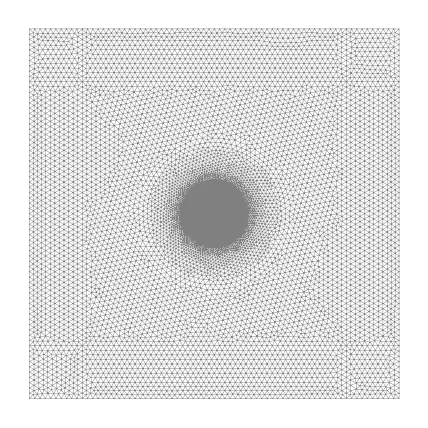

In [ ]:
pmesh = 10                       # elements per local wavelength
lmin = wl / pmesh
for pml in geom.pmls:
    geom.set_size(pml, lmin)
geom.set_size("box", lmin / eps_bg**0.5)
geom.set_size("rod", lmin / eps_rod.real**0.5)
geom.build()
print(f"{geom.mesh.num_cells()} triangles")

geom.plot_mesh(lw=0.3)
plt.axis("off")
plt.show()

### The incident wave

The rod is lit by a unit-amplitude plane wave travelling along $+y$,

$$
u_0(x, y) = e^{-jk_0 y}.
$$

In TM it is the electric field $E_z$ of the wave, in TE its magnetic field $H_z$.

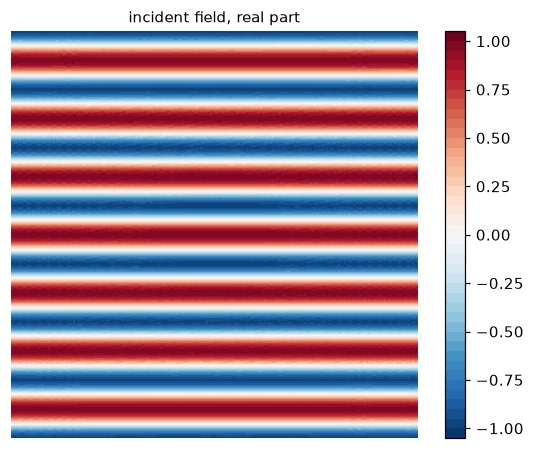

In [ ]:
pw = gy.PlaneWave(wavelength=wl, angle=0, dim=2, domain=geom.mesh, degree=2)

from gyptis.plot import plot

V = gy.dolfin.FunctionSpace(geom.mesh, "CG", 2)
plot(gy.utils.project_iterative(pw.expression.real, V), cmap="RdBu_r")
plt.axis("off")
plt.title("incident field, real part")
plt.show()

### Weak form and solution (TM polarization)

Finite elements solve the equation in its *weak form*: multiply by a test function $v$, integrate over the domain $\Omega$ (box and PMLs), and integrate by parts. We look for $u_s$ such that, for every test function $v$,

$$
\int_\Omega \left[\xi\,\nabla u_s\cdot\nabla v - k_0^2\,\chi\, u_s\, v\right] \mathrm{d}\Omega
= -\int_{\text{rod}} \left[(\xi - \xi_b)\,\nabla u_0\cdot\nabla v - k_0^2\,(\chi - \chi_b)\, u_0\, v\right] \mathrm{d}\Omega.
$$

Writing $u_s$ on a basis of quadratic polynomials (`degree=2`) turns this into a sparse linear system, which gyptis assembles and solves. We start with TM polarization, where $u = E_z$.

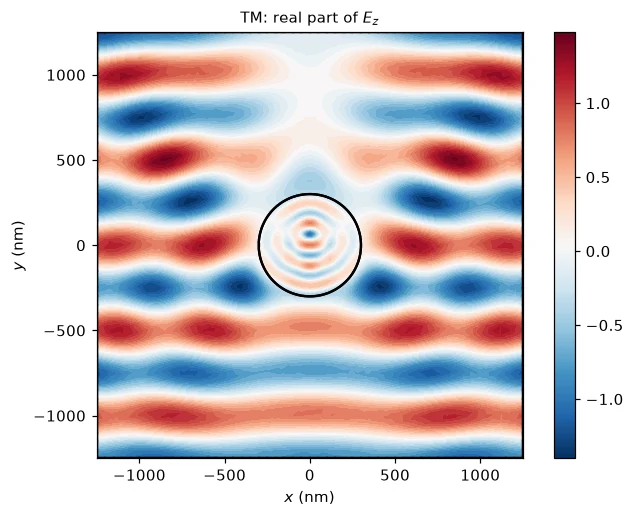

In [ ]:
epsilon = dict(box=eps_bg, rod=eps_rod)
mu = dict(box=1, rod=1)

sTM = gy.Scattering(geom, epsilon, mu, pw, degree=2, polarization="TM")
sTM.solve()

sTM.plot_field()
geom.plot_subdomains()
plt.xlabel("$x$ (nm)")
plt.ylabel("$y$ (nm)")
plt.title("TM: real part of $E_z$")
plt.tight_layout()
plt.show()

Inside the rod the field oscillates about four times faster than outside, as expected from $n \approx 4.3$. Behind the rod (towards $+y$) the stripes fade: the rod casts a shadow. On either side, the scattered wave interferes with the incident one and bends the wavefronts.

### Cross sections and the energy balance

How much light does the rod remove from the beam? We measure energy fluxes through the circle $\Gamma$ of radius $R_\text{calc}$, using the time-averaged Poynting vector $\langle\mathbf{S}\rangle = \frac12\mathrm{Re}\left(\mathbf{E}\times\mathbf{H}^*\right)$. Dividing by the incident intensity $S_0$ gives cross sections, which in 2D have the dimension of a length (power per unit length of rod, divided by power per unit area):

$$
\sigma_s = \frac{1}{S_0}\oint_\Gamma \langle\mathbf{S}_s\rangle\cdot\mathbf{n}\,\mathrm{d}\ell,
\qquad
\sigma_a = -\frac{1}{S_0}\oint_\Gamma \langle\mathbf{S}\rangle\cdot\mathbf{n}\,\mathrm{d}\ell.
$$

The scattering cross section $\sigma_s$ counts the power carried away by the scattered field, and the absorption cross section $\sigma_a$ the net power flowing into the rod. The extinction cross section $\sigma_e$ is the total power taken out of the incident beam. gyptis computes it independently, from the interference between incident and scattered fields,

$$
\sigma_e = -\frac{1}{S_0}\oint_\Gamma \tfrac12\mathrm{Re}\left(\mathbf{E}_0\times\mathbf{H}_s^* + \mathbf{E}_s\times\mathbf{H}_0^*\right)\cdot\mathbf{n}\,\mathrm{d}\ell.
$$

Energy conservation demands $\sigma_e = \sigma_s + \sigma_a$, so comparing the two sides is a useful check of the numerics.

In [ ]:
cs = {}
cs["TM"] = sTM.get_cross_sections()
for name, value in cs["TM"].items():
    print(f"sigma_{name[0]} = {value:7.1f} nm")
print(f"(sigma_s + sigma_a) / sigma_e = {(cs['TM']['scattering'] + cs['TM']['absorption']) / cs['TM']['extinction']:.5f}")

sigma_s =   998.4 nm
sigma_a =   397.1 nm
sigma_e =  1394.4 nm
(sigma_s + sigma_a) / sigma_e = 1.00076


The balance holds to better than 0.1 %. The extinction cross section is also more than twice the rod's diameter (600 nm): a resonant object can intercept light from a region wider than its own geometric shadow.

### Checking against the exact solution

For a circular cylinder, the scattering problem has an exact solution, the Lorenz–Mie series. The field inside the rod is expanded on Bessel functions and the scattered field on outgoing cylindrical waves (Hankel functions), one term per angular order $n$; matching the fields at $r = R$ gives each coefficient in closed form. Textbooks (Bohren and Huffman, chapter 8) write the result in the opposite time convention, $e^{-i\omega t}$, where outgoing waves are $H_n = H^{(1)}_n$. With the size parameter $x = k_0R$, the relative index $m = n_\text{rod}/n_\text{bg}$ and primes for derivatives,

$$
\text{TM:}\quad b_n = \frac{J_n(mx)\,J_n'(x) - m\,J_n'(mx)\,J_n(x)}{J_n(mx)\,H_n'(x) - m\,J_n'(mx)\,H_n(x)},
$$

$$
\text{TE:}\quad a_n = \frac{m\,J_n'(x)\,J_n(mx) - J_n(x)\,J_n'(mx)}{m\,J_n(mx)\,H_n'(x) - J_n'(mx)\,H_n(x)}.
$$

The cross sections follow by summing over all orders $n \in \mathbb{Z}$ (with $c_{-n} = c_n$, and $c = b$ or $a$):

$$
\sigma_s = \frac{4}{k_0}\sum_{n=-\infty}^{\infty} |c_n|^2,
\qquad
\sigma_e = \frac{4}{k_0}\,\mathrm{Re}\sum_{n=-\infty}^{\infty} c_n,
\qquad
\sigma_a = \sigma_e - \sigma_s.
$$

Switching between the two time conventions amounts to complex conjugation, so we evaluate these formulas with $\varepsilon^*$ instead of $\varepsilon$.

In [ ]:
from scipy.special import h1vp, hankel1, jv, jvp


def mie_cylinder(wavelength, radius, eps, polarization, nmax=40):
    # Exact cross sections of a cylinder in vacuum, per unit length.
    x = 2 * np.pi / wavelength * radius
    m = np.sqrt(np.conj(eps))           # textbook convention is exp(-i w t)
    n = np.arange(nmax + 1)
    J, dJ = jv(n, x), jvp(n, x)
    Jm, dJm = jv(n, m * x), jvp(n, m * x)
    H, dH = hankel1(n, x), h1vp(n, x)
    if polarization == "TM":
        c = (Jm * dJ - m * dJm * J) / (Jm * dH - m * dJm * H)
    else:
        c = (m * dJ * Jm - J * dJm) / (m * Jm * dH - dJm * H)
    weight = np.where(n == 0, 1, 2)     # orders n and -n contribute equally
    scattering = 2 * wavelength / np.pi * np.sum(weight * abs(c) ** 2)
    extinction = 2 * wavelength / np.pi * np.sum(weight * c).real
    return dict(scattering=scattering, absorption=extinction - scattering, extinction=extinction)


def compare(polarization):
    exact = mie_cylinder(wl, R, eps_rod, polarization)
    print(f"{polarization}            FEM      exact    error")
    for name in exact:
        fem = cs[polarization][name]
        print(f"{name:<12} {fem:7.1f}  {exact[name]:7.1f}  {100 * (fem / exact[name] - 1):+5.2f} %")


compare("TM")

TM            FEM      exact    error
scattering     998.4    978.8  +2.00 %
absorption     397.1    389.5  +1.94 %
extinction    1394.4   1368.3  +1.91 %


The finite element result agrees with the exact series to about 2 %, with a mesh of only ten elements per local wavelength. We will see below where the remaining error comes from and how to reduce it.

### TE polarization

Now the magnetic field points along the rod, $u = H_z$, and the roles of $\varepsilon$ and $\mu$ are swapped: $\xi = \varepsilon^{-1}$, $\chi = \mu$. Only the `polarization` argument changes.

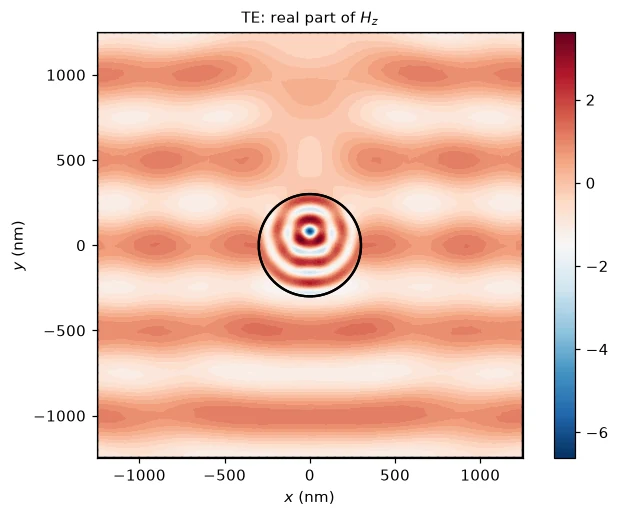

TE            FEM      exact    error
scattering     732.5    716.7  +2.21 %
absorption     421.9    413.0  +2.16 %
extinction    1153.4   1129.7  +2.10 %


In [ ]:
sTE = gy.Scattering(geom, epsilon, mu, pw, degree=2, polarization="TE")
sTE.solve()

sTE.plot_field()
geom.plot_subdomains()
plt.xlabel("$x$ (nm)")
plt.ylabel("$y$ (nm)")
plt.title("TE: real part of $H_z$")
plt.tight_layout()
plt.show()

cs["TE"] = sTE.get_cross_sections()
compare("TE")

In TE the electric field lies in the plane and crosses the rod's surface, where its normal component jumps by a factor $\varepsilon$. The pattern inside the rod is very different: the magnetic field there reaches several times the incident amplitude, a sign that this polarization excites a resonance of the rod more strongly. The cross sections differ too: a rod responds differently to the two polarizations.

### A spectrum from the exact solution

The series is cheap to evaluate, so we can scan the wavelength to see where our simulation sits. We plot the extinction efficiency $Q_e = \sigma_e / 2R$, the extinction cross section relative to the rod's diameter. For simplicity the permittivity is kept at its 500 nm value; a real silicon spectrum would also include the dispersion of $n$.

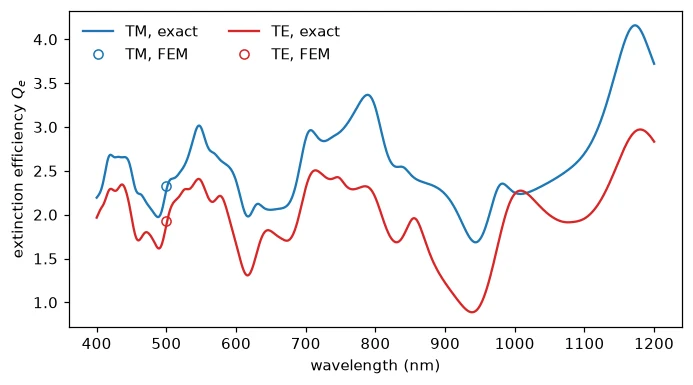

In [ ]:
wavelengths = np.linspace(400, 1200, 801)
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for polarization, color in (("TM", "tab:blue"), ("TE", "tab:red")):
    Qe = [mie_cylinder(w, R, eps_rod, polarization)["extinction"] / (2 * R) for w in wavelengths]
    ax.plot(wavelengths, Qe, color=color, label=f"{polarization}, exact")
    ax.plot(wl, cs[polarization]["extinction"] / (2 * R), "o", color=color, mfc="none", label=f"{polarization}, FEM")
ax.set_xlabel("wavelength (nm)")
ax.set_ylabel("extinction efficiency $Q_e$")
ax.legend(frameon=False, ncol=2)
plt.tight_layout()
plt.show()

The peaks and shoulders are the rod's Mie resonances: standing waves that fit inside the silicon, each associated with one cylindrical order $n$. At short wavelengths many orders are excited at once and the spectrum is busy. As the wavelength grows, fewer orders fit inside the rod and the features become fewer and broader, up to the strong low-order resonances in the near infrared. Our two simulations sit close to the exact curves.

### How accurate is the mesh?

The 2 % difference comes from discretization. Refining the mesh should bring the finite element result towards the exact one. We rebuild the geometry with an increasing number of elements per local wavelength and track the error on the TM extinction cross section.

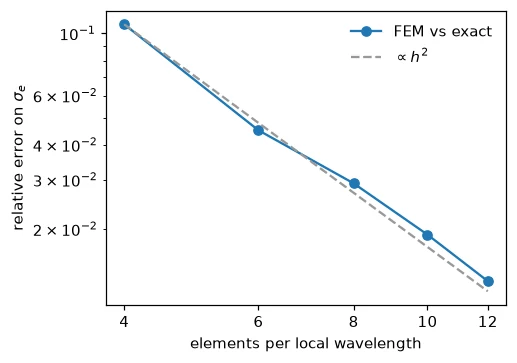

In [ ]:
def extinction_tm(pmesh):
    g = gy.BoxPML(dim=2, box_size=(5 * wl, 5 * wl), pml_width=(wl, wl), Rcalc=0.9 * 3 * wl / 2)
    rod = g.add_circle(0, 0, 0, R)
    rod, *bg = g.fragment(rod, g.box)
    g.add_physical(bg, "box")
    g.add_physical(rod, "rod")
    for pml in g.pmls:
        g.set_size(pml, wl / pmesh)
    g.set_size("box", wl / pmesh)
    g.set_size("rod", wl / pmesh / eps_rod.real**0.5)
    g.build()
    source = gy.PlaneWave(wavelength=wl, angle=0, dim=2, domain=g.mesh, degree=2)
    s = gy.Scattering(g, epsilon, mu, source, degree=2, polarization="TM")
    s.solve()
    return s.extinction_cross_section()


exact = mie_cylinder(wl, R, eps_rod, "TM")["extinction"]
pmeshes = [4, 6, 8, 10, 12]
errors = [abs(extinction_tm(p) / exact - 1) for p in pmeshes]

p = np.array(pmeshes)
fig, ax = plt.subplots(figsize=(4.8, 3.4))
ax.loglog(p, errors, "o-", label="FEM vs exact")
ax.loglog(p, errors[0] * (p / p[0]) ** -2, "--", color="0.6", label="$\\propto h^2$")
ax.set_xticks(p, [str(x) for x in p])
ax.xaxis.set_minor_locator(plt.NullLocator())
ax.set_xlabel("elements per local wavelength")
ax.set_ylabel("relative error on $\\sigma_e$")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

The error drops steadily, roughly as $h^2$ where $h$ is the element size. That rate points to the geometry rather than the field: the circle is represented by straight-sided triangles, so the meshed rod is a polygon whose area approaches $\pi R^2$ only as $h^2$, while quadratic elements approximate a smooth field faster. Curved (isoparametric) elements would remove most of this error.

### Things to try

Every cell above is editable. A few ideas:

- **Size**: change `R` and watch the cross sections follow the resonances of the spectrum. A thin rod ($R = 30$ nm) is much smaller than the wavelength and scatters weakly.
- **Material**: replace silicon by glass (`n_si = 1.5`) to remove absorption, then check that $\sigma_a$ vanishes.
- **Resonance**: pick a wavelength at a peak of the spectrum and compare the field inside the rod with the one at 500 nm. Remember to rebuild the mesh, which depends on `wl`.
- **Angle**: rotate the incident wave with `angle` in `gy.PlaneWave`. For a circular rod nothing should change; for an elliptical one (`geom.add_ellipse`) it does.
- **PMLs**: make `pml_width` very thin, or the stretch weak (`pml_stretch=1 - 0.1j` in `gy.Scattering`), and see how reflections from the box edges spoil the energy balance.